# Exercice 3 du TD/TP2

## Version du cours

In [1]:
def fusion(l1, l2):
    l_fusion = []
    i = 0
    j = 0
    
    while i < len(l1) and j < len(l2):
        if l1[i] < l2[j]:
            l_fusion.append(l1[i])
            i += 1
        else:
            l_fusion.append(l2[j])
            j += 1

    while i < len(l1):
        l_fusion.append(l1[i])
        i += 1

    while j < len(l2):
        l_fusion.append(l2[j])
        j += 1
        
    return l_fusion

In [2]:
def tri_fusion(l):
    if len(l) == 1:
        return l
    else:
        milieu = len(l) // 2
        l1 = tri_fusion(l[:milieu])
        l2 = tri_fusion(l[milieu:])
        return fusion(l1, l2)

In [3]:
l = [7, 5, 3, 0, 1, 6, 4, 2]

l_triee = tri_fusion(l)
print(l_triee)

[0, 1, 2, 3, 4, 5, 6, 7]


In [4]:
import time
import random
import numpy as np
from tqdm import tqdm

times = []
sizes = range(1, 100000, 100)

for element in tqdm(sizes):
    to_sort = [random.randint(0, element) for _ in range(element)]
    start = time.time()
    tri_fusion(to_sort)
    exec_time = time.time() - start
    times.append(exec_time)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [01:15<00:00, 13.24it/s]


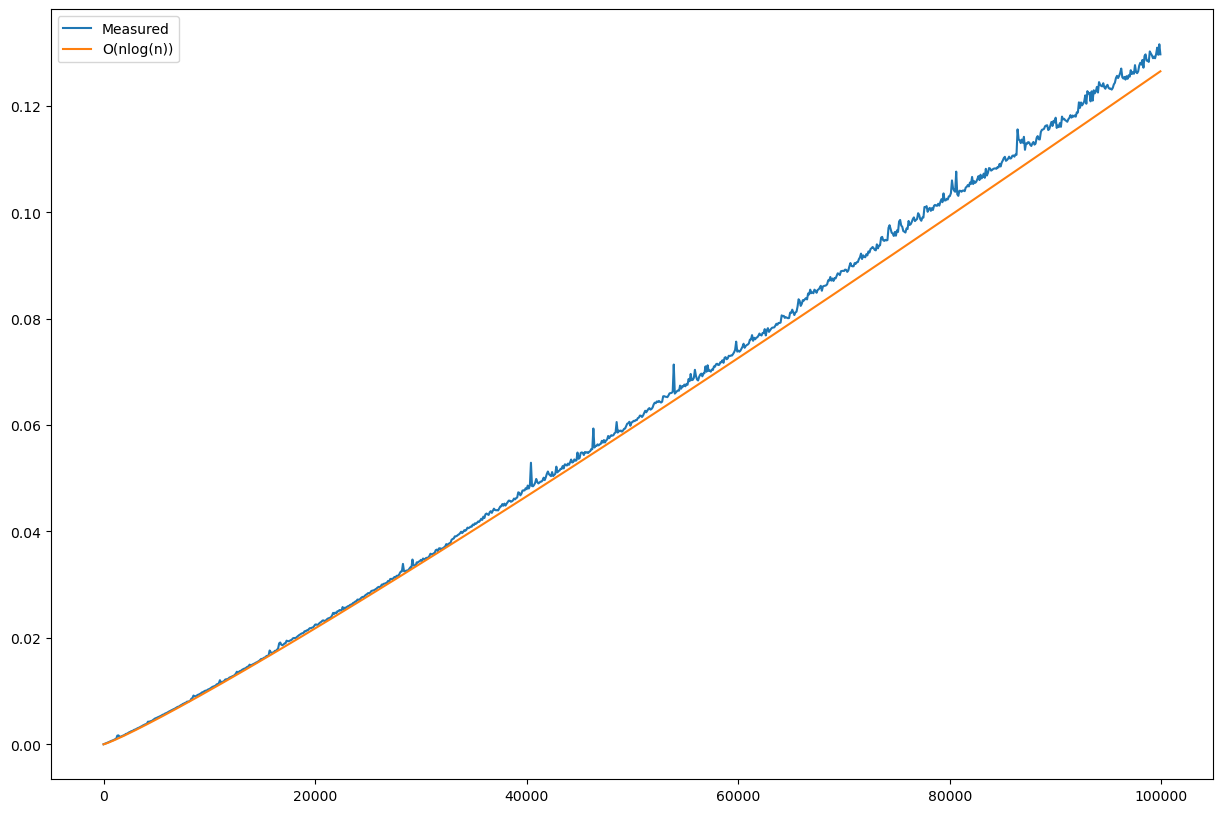

In [5]:
import matplotlib.pyplot as plt
from math import log

plt.figure(figsize=(15, 10))
plt.plot(sizes, times)
plt.plot(sizes, [1.1e-7*size*log(size) for size in sizes])
plt.legend(['Measured', 'O(nlog(n))'])
plt.show()

**Question 4.** On voit que dans la fonction « fusion », un tableau de taille len(l1)+len(l2) est créé en plus du tableau l. Le plus grand tableau créé de la sorte sera de taille $\frac{n}{2} + \frac{n}{2} = n$, où $n$ est la taille de l. La complexité temporelle est donc en $O(n)$.

## Version efficace en espace : le tri fusion en place

In [6]:
def tri_fusion_en_place(l, i, j):
    if i < j:
        milieu = (i + j) // 2
        l = tri_fusion_en_place(l, i, milieu)
        l = tri_fusion_en_place(l, milieu + 1, j)
        l = fusion_en_place(l, i, milieu + 1, j)
    return l

In [7]:
def fusion_en_place(l, i, milieu, j):
    while i < milieu and milieu <= j:
        if l[i] <= l[milieu]:
            i += 1
        else:
            permutation_droite(l, i, milieu)
            i += 1
            milieu += 1
    return l

In [8]:
def permutation_droite(l, i, j):
    tmp = l[j]
    for k in range(0, (j-i)):
        l[j-k] = l[j-k-1]
    l[i] = tmp
    return l

In [9]:
def tri_fusion_en_place_wrapper(l):
    return tri_fusion_en_place(l, 0, len(l) - 1)

In [10]:
l = [7, 5, 3, 0, 1, 6, 4, 2]

l_triee = tri_fusion_en_place_wrapper(l)
print(l_triee)

[0, 1, 2, 3, 4, 5, 6, 7]


In [11]:
times = []
sizes = range(1, 10000, 100)

for element in tqdm(sizes):
    to_sort = [random.randint(0, element) for _ in range(element)]
    start = time.time()
    tri_fusion_en_place_wrapper(to_sort)
    exec_time = time.time() - start
    times.append(exec_time)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:31<00:00,  3.16it/s]


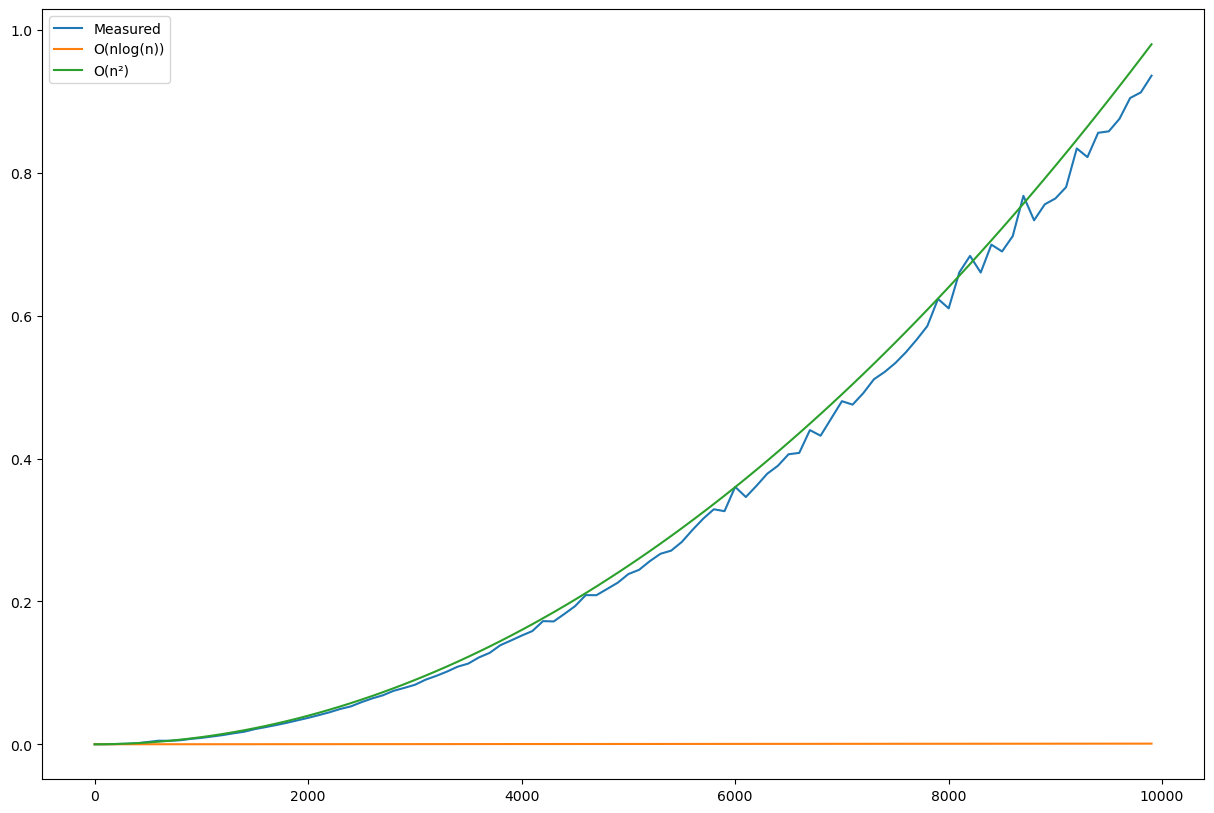

In [12]:
import matplotlib.pyplot as plt
from math import log

plt.figure(figsize=(15, 10))
plt.plot(sizes, times)
plt.plot(sizes, [1e-8*size*log(size) for size in sizes])
plt.plot(sizes, [1e-8*size**2 for size in sizes])
plt.legend(['Measured', 'O(nlog(n))', 'O(n²)'])
plt.show()